# What the three trained models output

This notebook is a look at the work so far. It does not train anything.

The project output for one clip is a list of events. Each event has a class name, a start time in seconds, an end time in seconds, and a score from 0 to 1. Several events may overlap.

Three models have been trained. Each one reads the same log-mel frames and emits that event list. The notebook loads the saved weights, plays one wav, and puts the three event lists next to the reference labels.

Kernel: `nndl-project`. That kernel is the project `.venv`. In JupyterLab, select it if this notebook does not already use it. Start JupyterLab from the project root with `uv run jupyter lab`.

Change `CLIP_WAV` in the cell marked "Set the clip", then run all cells from the top. The full-split score tables do not change when you change the clip. Only the player, the event tables, and the timeline change.


## What has been done

The task is multi-label classification on short frames, for domestic sound. A clip is about 10 seconds. Several sounds can be active at once. For every 20 ms frame, each of the ten Domestic Environment Sound Event Detection (DESED) classes is yes or no. The training loss sees those yes/no labels. It does not see a numeric start or end. After classification, frames that stay active are grouped into an event. That event list is the output.

The ten names are Alarm_bell_ringing, Blender, Cat, Dishes, Dog, Electric_shaver_toothbrush, Frying, Running_water, Speech, and Vacuum_cleaner.

Training and scoring use only the synthetic clips. Detection and Classification of Acoustic Scenes and Events (DCASE) public eval, the dcase2019 condition folders, the real DESED lists, and Freesound Dataset 50K (FSD50K) are not used here.

Three models are finished, in this order:

1. A logistic baseline. One logistic regression per class. Each input row is one log-mel frame. The saved file is the full 10000-clip fit.
2. A context multilayer perceptron (MLP). Each frame is classified together with five frames on either side, about 220 ms. The run was stopped after epoch 432 of a 1000-epoch request. The saved model is that last finished epoch.
3. A frame gated recurrent unit (GRU). One bidirectional GRU reads all 497 frames of the clip, then a linear layer emits ten logits at every frame. The run finished epoch 30 of 30. The saved model is that last epoch.

All three use the same decode: a median filter of 11 frames, then a threshold of 0.5. The threshold was not tuned on the validation split. F1, where it appears below, is the harmonic mean of precision and recall.


## Which directories the files come from

The wavs and the labels live under `data/raw/desed/dcase_synth`. Train and validation both contain a file named `0.wav`. Those are different recordings. The folder in the path is what picks the recording.

Allowed clip directories, and only these:

- Validation wavs: `data/raw/desed/dcase_synth/audio/validation/synthetic21_validation/soundscapes`
- Validation labels: `data/raw/desed/dcase_synth/metadata/validation/synthetic21_validation/soundscapes.tsv`
- Train wavs: `data/raw/desed/dcase_synth/audio/train/synthetic21_train/soundscapes`
- Train labels: `data/raw/desed/dcase_synth/metadata/train/synthetic21_train/soundscapes.tsv`

The official scores use every validation wav, `0.wav` through `2499.wav`, and the validation label table. They are already written in:

- `reports/baseline_logistic.md`
- `reports/context_mlp.md`
- `reports/frame_gru.md`

The weights are local cache files. Git does not track them.

- Logistic: `data/cache/logmel_v1/train_10000/models.joblib`
- Context MLP: `data/cache/context_mlp/full/model_last.pt`
- Frame GRU: `data/cache/frame_gru/full/model_last.pt`

When the chosen wav is one of the cached clips, its log-mel frames are read from `data/cache/logmel_v1/validation_2500` or `data/cache/logmel_v1/train_10000`. The small `limit200` checkpoints and `models_smoke.joblib` are pipeline checks. This notebook does not load them.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from IPython.display import Audio, display
from scipy.optimize import linear_sum_assignment

pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 120)


def find_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "data" / "raw").is_dir():
            return cand
    raise FileNotFoundError(
        "Could not find the project. Start JupyterLab from neural_networks_and_deep_learning_project."
    )


ROOT = find_root()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from nndl_project.constants import (
    CLASSES,
    MEDIAN_FRAMES,
    N_FRAMES,
    N_MELS,
    OFFSET_COLLAR_FRACTION,
    OFFSET_COLLAR_SECONDS,
    ONSET_COLLAR_SECONDS,
    THRESHOLD,
)
from nndl_project.context import CONTEXT_RADIUS, ContextMLP, n_inputs, stack_context
from nndl_project.data import Event, events_for_split, split_paths
from nndl_project.decode import decode_events
from nndl_project.features import load_mono_16k, log_mel
from nndl_project.sequence import FrameGRU

VAL_AUDIO, VAL_TSV = split_paths("validation")
TRAIN_AUDIO, TRAIN_TSV = split_paths("train")
REPORTS = {
    "Logistic baseline": ROOT / "reports" / "baseline_logistic.md",
    "Context MLP": ROOT / "reports" / "context_mlp.md",
    "Frame GRU": ROOT / "reports" / "frame_gru.md",
}
MODEL_FILES = {
    "Logistic baseline": ROOT / "data" / "cache" / "logmel_v1" / "train_10000" / "models.joblib",
    "Context MLP": ROOT / "data" / "cache" / "context_mlp" / "full" / "model_last.pt",
    "Frame GRU": ROOT / "data" / "cache" / "frame_gru" / "full" / "model_last.pt",
}
CACHE_DIRS = {
    "validation": ROOT / "data" / "cache" / "logmel_v1" / "validation_2500",
    "train": ROOT / "data" / "cache" / "logmel_v1" / "train_10000",
}

print(f"Project root: {ROOT}")
print(f"Validation wav directory: {VAL_AUDIO}")
print(f"Validation label table: {VAL_TSV}")
print(f"Train wav directory: {TRAIN_AUDIO}")
print(f"Train label table: {TRAIN_TSV}")
print("Score reports:")
for name, path in REPORTS.items():
    print(f"  {name}: {path}")
print("Saved models:")
for name, path in MODEL_FILES.items():
    print(f"  {name}: {path}  exists={path.is_file()}")


Project root: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project
Validation wav directory: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\validation\synthetic21_validation\soundscapes
Validation label table: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\metadata\validation\synthetic21_validation\soundscapes.tsv
Train wav directory: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\train\synthetic21_train\soundscapes
Train label table: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\metadata\train\synthetic21_train\soundscapes.tsv
Score reports:
  Logistic baseline: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\reports\baseline_logistic.md
  Context MLP: C:

## Full validation scores

These tables are the official comparison. They were computed on all 2500 `synthetic21_validation` clips. Changing the clip path below does not recompute them.

Segment F1 cuts each clip into 1 second blocks. A block is a hit for a class when the reference and the model both have that class somewhere in the block. The edges can be off by almost a second and the block can still count as correct.

Event F1 looks at each whole sound. A predicted event matches a reference event of the same class only when the start is within 200 ms and the end is within the larger of 200 ms and 20 percent of the reference length. One prediction is paired with at most one reference. A second copy is a false event. A start that is late by 400 ms is a miss, even when the class is right.

Micro F1 pools every class into one count. Macro F1 averages the ten class F1 values. A high recall with a low precision means the model marks too much time, or too many short pieces, as active.


In [2]:
def table_after(text: str, marker: str) -> dict[str, float]:
    """Read the F1 column from the last markdown table under a heading."""
    lines = text.splitlines()
    starts = [i for i, line in enumerate(lines) if line.strip().lstrip("#").strip() == marker]
    if not starts:
        raise ValueError(f"no table heading {marker!r}")
    rows: list[list[str]] = []
    for line in lines[starts[-1] + 1 :]:
        if line.startswith("|"):
            rows.append([cell.strip() for cell in line.strip().strip("|").split("|")])
        elif rows:
            break
    if len(rows) < 3:
        raise ValueError(f"table under {marker!r} is incomplete")
    header = rows[0]
    f1_index = header.index("f1")
    class_index = header.index("class")
    parsed: dict[str, float] = {}
    for row in rows[2:]:
        parsed[row[class_index]] = float(row[f1_index])
    return parsed


summary_rows = []
class_rows = []
for model_name, path in REPORTS.items():
    text = path.read_text(encoding="utf-8")
    segment = table_after(text, "Segment scores")
    event = table_after(text, "Event scores")
    summary_rows.append(
        {
            "model": model_name,
            "segment micro F1": segment["micro"],
            "segment macro F1": segment["macro f1"],
            "event micro F1": event["micro"],
            "event macro F1": event["macro f1"],
        }
    )
    for label in CLASSES:
        class_rows.append(
            {
                "class": label,
                "model": model_name,
                "segment F1": segment[label],
                "event F1": event[label],
            }
        )

summary = pd.DataFrame(summary_rows).set_index("model")
by_class = pd.DataFrame(class_rows)
segment_wide = by_class.pivot(index="class", columns="model", values="segment F1")
event_wide = by_class.pivot(index="class", columns="model", values="event F1")
column_order = ["Logistic baseline", "Context MLP", "Frame GRU"]
segment_wide = segment_wide[column_order]
event_wide = event_wide[column_order]

print("Summary on all 2500 synthetic21_validation clips")
display(summary.round(3))
print("Segment F1 by class")
display(segment_wide.round(3))
print("Event F1 by class")
display(event_wide.round(3))

logistic = summary.loc["Logistic baseline"]
mlp = summary.loc["Context MLP"]
gru = summary.loc["Frame GRU"]
print(
    "Segment micro F1 is "
    f"{logistic['segment micro F1']:.3f} for the logistic model, "
    f"{mlp['segment micro F1']:.3f} for the context MLP, and "
    f"{gru['segment micro F1']:.3f} for the frame GRU."
)
print(
    "Event micro F1 is "
    f"{logistic['event micro F1']:.3f} for the logistic model, "
    f"{mlp['event micro F1']:.3f} for the context MLP, and "
    f"{gru['event micro F1']:.3f} for the frame GRU."
)
print(
    "The frame GRU is ahead on all four summary numbers. "
    "Event micro F1 is still low for every model: most predicted events do not land on a reference event."
)
gain = (event_wide["Frame GRU"] - event_wide["Logistic baseline"]).sort_values(ascending=False)
print("Largest event-F1 gains from the logistic model to the frame GRU:")
for label, value in gain.head(3).items():
    print(
        f"  {label}: logistic {event_wide.loc[label, 'Logistic baseline']:.3f}, "
        f"GRU {event_wide.loc[label, 'Frame GRU']:.3f}, gain {value:.3f}"
    )
best_event = event_wide["Frame GRU"].idxmax()
print(
    f"The highest frame-GRU event F1 is {best_event} at {event_wide.loc[best_event, 'Frame GRU']:.3f}. "
    "Long steady sounds move more than short bursts. "
    "The loss scores 20 ms frames, and the fixed threshold of 0.5 still emits short fragments."
)


Summary on all 2500 synthetic21_validation clips


,segment micro F1,segment macro F1,event micro F1,event macro F1
model,,,,
Logistic baseline,0.393,0.289,0.044,0.030
Context MLP,0.398,0.349,0.053,0.041
Frame GRU,0.509,0.438,0.104,0.096


Segment F1 by class


model,Logistic baseline,Context MLP,Frame GRU
class,,,
Alarm_bell_ringing,0.105,0.350,0.272
Blender,0.143,0.267,0.345
Cat,0.249,0.202,0.323
Dishes,0.194,0.229,0.269
Dog,0.230,0.206,0.287
Electric_shaver_toothbrush,0.300,0.313,0.526
Frying,0.401,0.490,0.611
Running_water,0.248,0.269,0.387
Speech,0.778,0.836,0.804


Event F1 by class


model,Logistic baseline,Context MLP,Frame GRU
class,,,
Alarm_bell_ringing,0.000,0.017,0.014
Blender,0.000,0.009,0.040
Cat,0.009,0.019,0.042
Dishes,0.049,0.061,0.047
Dog,0.044,0.035,0.025
Electric_shaver_toothbrush,0.018,0.017,0.146
Frying,0.029,0.024,0.194
Running_water,0.004,0.006,0.060
Speech,0.146,0.212,0.205


Segment micro F1 is 0.393 for the logistic model, 0.398 for the context MLP, and 0.509 for the frame GRU.
Event micro F1 is 0.044 for the logistic model, 0.053 for the context MLP, and 0.104 for the frame GRU.
The frame GRU is ahead on all four summary numbers. Event micro F1 is still low for every model: most predicted events do not land on a reference event.
Largest event-F1 gains from the logistic model to the frame GRU:
  Vacuum_cleaner: logistic 0.004, GRU 0.186, gain 0.182
  Frying: logistic 0.029, GRU 0.194, gain 0.165
  Electric_shaver_toothbrush: logistic 0.018, GRU 0.146, gain 0.128
The highest frame-GRU event F1 is Speech at 0.205. Long steady sounds move more than short bursts. The loss scores 20 ms frames, and the fixed threshold of 0.5 still emits short fragments.


## Set the clip

Edit the path in the next cell, then run all cells from the top.

The path may be relative to the project root, or it may be absolute. It must be a wav inside one of the two soundscapes directories printed above. `0.wav` in the validation directory and `0.wav` in the train directory are different clips. A train clip is shown with its own labels, and it is not part of the 2500-clip score.

Public eval and the dcase2019 folders are rejected on purpose. Those sets stay closed.


In [3]:
# Edit this path, then run all cells from the top.
# Relative paths start at the project root.
CLIP_WAV = (
    "data/raw/desed/dcase_synth/audio/validation/"
    "synthetic21_validation/soundscapes/0.wav"
)


In [4]:
chosen = Path(CLIP_WAV)
if not chosen.is_absolute():
    chosen = ROOT / chosen
chosen = chosen.resolve()
if not chosen.is_file():
    raise FileNotFoundError(f"CLIP_WAV is not a file: {chosen}")
if chosen.suffix.lower() != ".wav":
    raise ValueError("CLIP_WAV must be a .wav file")

allowed = {
    VAL_AUDIO.resolve(): ("validation", VAL_TSV),
    TRAIN_AUDIO.resolve(): ("train", TRAIN_TSV),
}
parent = chosen.parent.resolve()
if parent not in allowed:
    raise ValueError(
        "CLIP_WAV must be inside the synthetic21_validation soundscapes directory "
        f"({VAL_AUDIO}) or the synthetic21_train soundscapes directory ({TRAIN_AUDIO}). "
        "Public eval and the dcase2019 folders stay closed."
    )

SPLIT, LABEL_TSV = allowed[parent]
info = sf.info(str(chosen))
print(f"Chosen file: {chosen}")
print(f"Directory of this file: {chosen.parent}")
print(f"Split: synthetic21_{SPLIT}")
print(f"Label table for this file: {LABEL_TSV}")
print(
    f"Stored audio: {info.duration:.3f} s, {info.samplerate} Hz, {info.channels} channel(s). "
    "The player uses this file as stored. The models hear a 16 kHz one-channel copy of the same clip."
)
if SPLIT == "train":
    print(
        "This file is a training clip. The summary tables above do not include it. "
        "A file with the same name in the validation directory is a different recording."
    )
else:
    print(
        "This file is one validation clip. The summary tables above use every wav in this same directory."
    )


Chosen file: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\validation\synthetic21_validation\soundscapes\0.wav
Directory of this file: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\validation\synthetic21_validation\soundscapes
Split: synthetic21_validation
Label table for this file: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\metadata\validation\synthetic21_validation\soundscapes.tsv
Stored audio: 10.000 s, 44100 Hz, 1 channel(s). The player uses this file as stored. The models hear a 16 kHz one-channel copy of the same clip.
This file is one validation clip. The summary tables above use every wav in this same directory.


In [5]:
def cache_features(split: str, filename: str) -> np.ndarray | None:
    """Return one cached clip, or None when this name is not in that cache."""
    cache_dir = CACHE_DIRS[split]
    names_path = cache_dir / "names.txt"
    feature_path = cache_dir / "features.f32"
    names = [line.strip() for line in names_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    if filename not in names:
        return None
    index = names.index(filename)
    mapping = np.memmap(feature_path, dtype=np.float32, mode="r", shape=(len(names), N_FRAMES, N_MELS))
    row = np.array(mapping[index], dtype=np.float32)
    del mapping
    return row


def load_logistic(path: Path):
    import joblib

    bundle = joblib.load(path)
    saved_classes = tuple(bundle["classes"])
    if saved_classes != tuple(CLASSES):
        raise ValueError(f"logistic class order is {saved_classes}")
    mean = np.asarray(bundle["mean"], dtype=np.float32).reshape(-1)
    std = np.asarray(bundle["std"], dtype=np.float32).reshape(-1)
    print(f"Logistic baseline: {path}")
    print(f"  ten classifiers, training mean and standard deviation, threshold {bundle['threshold']}")
    return bundle["models"], mean, std


def load_mlp(path: Path):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    identity = payload["identity"]
    if int(identity["train_clips"]) != 10000:
        raise ValueError(f"refusing a checkpoint that is not the full MLP run: {identity}")
    radius = int(identity["context_radius"])
    model = ContextMLP(n_inputs(radius), hidden=int(identity["hidden"]))
    model.load_state_dict(payload["model_state"])
    model.eval()
    mean = np.asarray(payload["mean"], dtype=np.float32).reshape(-1)
    std = np.asarray(payload["std"], dtype=np.float32).reshape(-1)
    print(f"Context MLP: {path}")
    print(f"  last finished epoch {payload['epoch']}, context radius {radius}, hidden {identity['hidden']}")
    return model, mean, std, radius


def load_gru(path: Path):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    identity = payload["identity"]
    if int(identity["train_clips"]) != 10000:
        raise ValueError(f"refusing a checkpoint that is not the full GRU run: {identity}")
    model = FrameGRU(hidden=int(identity["hidden"]))
    model.load_state_dict(payload["model_state"])
    model.eval()
    mean = np.asarray(payload["mean"], dtype=np.float32).reshape(-1)
    std = np.asarray(payload["std"], dtype=np.float32).reshape(-1)
    print(f"Frame GRU: {path}")
    print(f"  last finished epoch {payload['epoch']}, hidden {identity['hidden']} each direction")
    return model, mean, std


def probabilities_for_clip(raw: np.ndarray) -> dict[str, np.ndarray]:
    """Frame probabilities, shape (frames, classes), for the three official models."""
    logistic_models, logistic_mean, logistic_std = LOGISTIC
    design = ((raw - logistic_mean) / logistic_std).reshape(-1, N_MELS)
    logistic_prob = np.column_stack(
        [model.predict_proba(design)[:, 1] for model in logistic_models]
    ).astype(np.float32)

    mlp_model, mlp_mean, mlp_std, radius = MLP
    windows = stack_context((raw - mlp_mean) / mlp_std, radius)
    with torch.no_grad():
        mlp_logits = mlp_model(torch.from_numpy(np.ascontiguousarray(windows)))
        mlp_prob = torch.sigmoid(mlp_logits).cpu().numpy().astype(np.float32)

    gru_model, gru_mean, gru_std = GRU
    gru_input = torch.from_numpy(((raw - gru_mean) / gru_std).astype(np.float32)[None, :, :])
    with torch.no_grad():
        gru_logits = gru_model(gru_input)
        gru_prob = torch.sigmoid(gru_logits)[0].cpu().numpy().astype(np.float32)
    return {
        "Logistic baseline": logistic_prob,
        "Context MLP": mlp_prob,
        "Frame GRU": gru_prob,
    }


LOGISTIC = load_logistic(MODEL_FILES["Logistic baseline"])
MLP = load_mlp(MODEL_FILES["Context MLP"])
GRU = load_gru(MODEL_FILES["Frame GRU"])

cached = cache_features(SPLIT, chosen.name)
if cached is None:
    print(f"No cached row for {chosen.name} in {CACHE_DIRS[SPLIT]}. Computing log-mel from the wav.")
    raw_frames = log_mel(load_mono_16k(chosen))
else:
    print(f"Log-mel frames read from {CACHE_DIRS[SPLIT]} for {chosen.name}.")
    raw_frames = cached
print(f"Feature shape: {raw_frames.shape}. Expected ({N_FRAMES}, {N_MELS}).")

reference = events_for_split(SPLIT).get(chosen.name, [])
probabilities = probabilities_for_clip(raw_frames)
predictions = {
    name: decode_events(frame_prob, threshold=THRESHOLD, median_frames=MEDIAN_FRAMES)
    for name, frame_prob in probabilities.items()
}


Logistic baseline: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\cache\logmel_v1\train_10000\models.joblib
  ten classifiers, training mean and standard deviation, threshold 0.5
Context MLP: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\cache\context_mlp\full\model_last.pt
  last finished epoch 432, context radius 5, hidden 128


Frame GRU: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\cache\frame_gru\full\model_last.pt
  last finished epoch 30, hidden 64 each direction
Log-mel frames read from C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\cache\logmel_v1\validation_2500 for 0.wav.
Feature shape: (497, 64). Expected (497, 64).


In [6]:
def match_pairs(reference: list[Event], prediction: list[Event]) -> list[tuple[Event, Event]]:
    """One-to-one pairs that pass the same collar as the project event F1."""
    ref_groups = {label: [] for label in CLASSES}
    pred_groups = {label: [] for label in CLASSES}
    for event in reference:
        ref_groups[event.label].append(event)
    for event in prediction:
        pred_groups[event.label].append(event)
    pairs: list[tuple[Event, Event]] = []
    for label in CLASSES:
        refs = ref_groups[label]
        preds = pred_groups[label]
        if not refs or not preds:
            continue
        cost = np.ones((len(refs), len(preds)), dtype=np.float64)
        for ref_index, ref in enumerate(refs):
            allowed_offset = max(OFFSET_COLLAR_SECONDS, OFFSET_COLLAR_FRACTION * (ref.offset - ref.onset))
            for pred_index, pred in enumerate(preds):
                onset_ok = abs(pred.onset - ref.onset) <= ONSET_COLLAR_SECONDS
                offset_ok = abs(pred.offset - ref.offset) <= allowed_offset
                if onset_ok and offset_ok:
                    cost[ref_index, pred_index] = 0.0
        rows, cols = linear_sum_assignment(cost)
        for ref_index, pred_index in zip(rows, cols, strict=True):
            if cost[ref_index, pred_index] == 0.0:
                pairs.append((preds[pred_index], refs[ref_index]))
    return pairs


def event_table(events: list[Event], pairs: list[tuple[Event, Event]] | None = None) -> pd.DataFrame:
    matched = {}
    if pairs is not None:
        matched = {id(pred): ref for pred, ref in pairs}
    rows = []
    ordered = sorted(events, key=lambda event: (event.onset, event.label))
    for event in ordered:
        row = {
            "label": event.label,
            "start_sec": round(event.onset, 3),
            "end_sec": round(event.offset, 3),
        }
        if pairs is None:
            rows.append(row)
            continue
        row["score"] = round(float(event.score), 3)
        ref = matched.get(id(event))
        if ref is None:
            row["result"] = "extra event"
        else:
            row["result"] = f"matches reference {ref.onset:.3f}-{ref.offset:.3f}"
        rows.append(row)
    return pd.DataFrame(rows)


print(f"Player file: {chosen}")
print(f"Directory: {chosen.parent}")
display(Audio(filename=str(chosen)))

print(f"Reference labels from {LABEL_TSV}")
if reference:
    display(event_table(reference))
else:
    print("This filename has no strong labels in that table.")

PAIR_MAP = {}
for model_name in ("Logistic baseline", "Context MLP", "Frame GRU"):
    pairs = match_pairs(reference, predictions[model_name])
    PAIR_MAP[model_name] = pairs
    print(f"{model_name}: {len(predictions[model_name])} events, {len(pairs)} matched the reference")
    display(event_table(predictions[model_name], pairs))


Player file: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\validation\synthetic21_validation\soundscapes\0.wav
Directory: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\validation\synthetic21_validation\soundscapes


Reference labels from C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\metadata\validation\synthetic21_validation\soundscapes.tsv


,label,start_sec,end_sec
0,Dog,5.050,5.310
1,Speech,6.832,8.674
2,Dog,7.412,7.797


Logistic baseline: 24 events, 2 matched the reference


,label,start_sec,end_sec,score,result
0,Speech,2.90,3.06,0.664,extra event
1,Speech,3.50,3.86,0.617,extra event
2,Cat,3.58,3.66,0.503,extra event
3,Dog,3.58,3.66,0.502,extra event
4,Speech,4.06,4.24,0.732,extra event
5,Speech,4.56,5.76,0.739,extra event
6,Dog,4.60,4.70,0.520,extra event
7,Dog,4.96,5.16,0.604,matches reference 5.050-5.310
8,Cat,5.10,5.26,0.513,extra event
9,Dog,5.30,5.44,0.560,extra event


Context MLP: 23 events, 0 matched the reference


,label,start_sec,end_sec,score,result
0,Cat,0.00,0.08,0.626,extra event
1,Dog,3.44,3.80,0.563,extra event
2,Cat,3.98,4.14,0.533,extra event
3,Dog,4.56,5.48,0.666,extra event
4,Cat,4.62,5.30,0.640,extra event
5,Cat,5.90,6.14,0.624,extra event
6,Speech,6.08,6.14,0.548,extra event
7,Dog,6.22,6.24,0.569,extra event
8,Cat,6.42,7.20,0.578,extra event
9,Dog,6.58,6.80,0.539,extra event


Frame GRU: 6 events, 2 matched the reference


,label,start_sec,end_sec,score,result
0,Alarm_bell_ringing,2.90,3.02,0.536,extra event
1,Speech,4.66,5.32,0.539,extra event
2,Dog,4.98,5.46,0.548,matches reference 5.050-5.310
3,Speech,6.88,8.66,0.791,matches reference 6.832-8.674
4,Alarm_bell_ringing,8.22,8.40,0.519,extra event
5,Dog,9.46,9.84,0.722,extra event


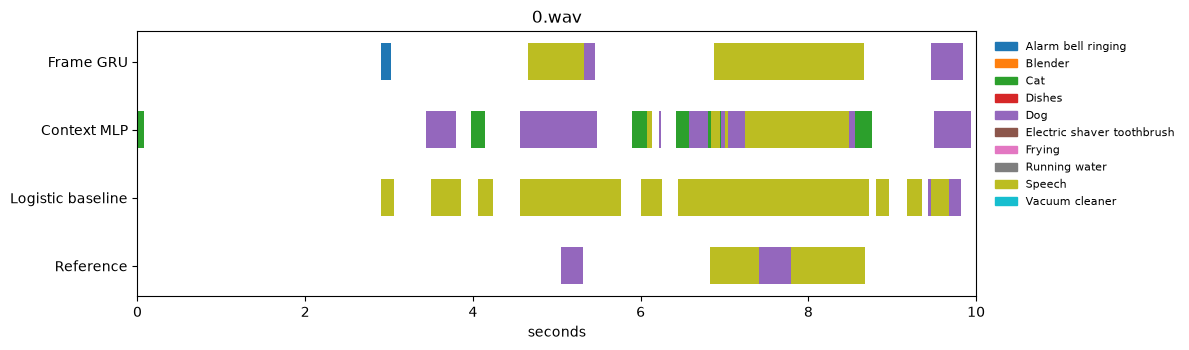

In [7]:
colors = {label: plt.get_cmap("tab10")(index) for index, label in enumerate(CLASSES)}
tracks = [("Reference", reference)] + [(name, predictions[name]) for name in ("Logistic baseline", "Context MLP", "Frame GRU")]
fig, ax = plt.subplots(figsize=(12, 3.6))
for row_index, (_title, events) in enumerate(tracks):
    for event in events:
        ax.barh(
            row_index,
            event.offset - event.onset,
            left=event.onset,
            height=0.55,
            color=colors[event.label],
            align="center",
        )
ax.set_yticks(range(len(tracks)), [title for title, _events in tracks])
ax.set_xlim(0, 10)
ax.set_xlabel("seconds")
ax.set_title(chosen.name)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=colors[label], label=label.replace("_", " "))
    for label in CLASSES
]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


## What this clip shows

The tables above are the project output for the wav you chose. "matches reference" means the start and the end both sit inside the event collar. "extra event" means this predicted piece was not paired with a reference event. A reference row that no model matches is a missed event.

The numbers in the summary tables are not this clip. They are all 2500 validation clips. One clip can look better or worse than that average. Use it to hear the mistake: a late start, a sound split into several pieces, or a class that is not in the reference.

Segment F1 can still be fair when those timing mistakes are smaller than one second. Event F1 counts them as misses. That is why every model here has a much higher segment score than event score, and why the frame GRU can be the best of the three while its event F1 stays low.


In [8]:
print(f"Clip: {chosen.name}")
print(f"Directory: {chosen.parent}")
print(f"Reference events: {len(reference)}")
for event in sorted(reference, key=lambda item: (item.onset, item.label)):
    print(f"  reference {event.label} {event.onset:.3f}-{event.offset:.3f}")

for model_name in ("Logistic baseline", "Context MLP", "Frame GRU"):
    pairs = PAIR_MAP[model_name]
    emitted = predictions[model_name]
    matched_refs = {id(ref) for _pred, ref in pairs}
    missed = [event for event in reference if id(event) not in matched_refs]
    print(
        f"{model_name} emitted {len(emitted)} events. "
        f"{len(pairs)} match a reference event. {len(emitted) - len(pairs)} are extras."
    )
    for pred, ref in sorted(pairs, key=lambda item: item[1].onset):
        print(
            f"  match: {pred.label} {pred.onset:.3f}-{pred.offset:.3f} "
            f"(score {pred.score:.3f}) matches reference {ref.onset:.3f}-{ref.offset:.3f}"
        )
    for event in sorted(missed, key=lambda item: item.onset):
        print(f"  missed reference: {event.label} {event.onset:.3f}-{event.offset:.3f}")

print(
    "Read a match as: the class is right, and both edges are close enough for the event score. "
    "Read an extra as a fragment the threshold kept. "
    "Read a miss as a reference sound whose edges this model did not land on."
)


Clip: 0.wav
Directory: C:\Users\gaura\Documents\grok_build_trial\neural_networks_and_deep_learning_project\data\raw\desed\dcase_synth\audio\validation\synthetic21_validation\soundscapes
Reference events: 3
  reference Dog 5.050-5.310
  reference Speech 6.832-8.674
  reference Dog 7.412-7.797
Logistic baseline emitted 24 events. 2 match a reference event. 22 are extras.
  match: Dog 4.960-5.160 (score 0.604) matches reference 5.050-5.310
  match: Dog 7.380-7.640 (score 0.535) matches reference 7.412-7.797
  missed reference: Speech 6.832-8.674
Context MLP emitted 23 events. 0 match a reference event. 23 are extras.
  missed reference: Dog 5.050-5.310
  missed reference: Speech 6.832-8.674
  missed reference: Dog 7.412-7.797
Frame GRU emitted 6 events. 2 match a reference event. 4 are extras.
  match: Dog 4.980-5.460 (score 0.548) matches reference 5.050-5.310
  match: Speech 6.880-8.660 (score 0.791) matches reference 6.832-8.674
  missed reference: Dog 7.412-7.797
Read a match as: the 